# Supervised Learning — Logistic Regression

Fraud classifier trained on the features built in `preprocessing.ipynb`, comparing three feature sets:

| Feature set | Columns |
|---|---|
| **Baseline** | transaction features only (amount, time, distance, category, gender, state, age, city size) |
| **+ KYC** | baseline + the synthetic KYC profile and profile-deviation features (`kyc_*`) |
| **+ KYC + behavioural** | the above + velocity and deviation-from-own-history features (`beh_*`) |

Input: `data/processed/fraudTrain_features.csv`, `data/processed/fraudTest_features.csv`

This notebook covers:
1. Loading the processed data
2. Train / validation / test split (out-of-time)
3. Model pipeline (scaling + class-weighted logistic regression)
4. Validation: choosing `C` and the decision threshold for each feature set
5. Test-set comparison of the three feature sets
6. The full model in detail
7. Coefficients and odds ratios
8. Results summary

**Metrics.** Fraud is ~0.5% of transactions, so accuracy is meaningless (predicting "never fraud" scores 99.5%). The main metric is **PR-AUC** (average precision), which focuses on how well the model ranks the rare fraud cases. A random classifier's PR-AUC equals the fraud rate (~0.004–0.006). ROC-AUC is reported for reference but looks optimistic on imbalanced data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
%matplotlib inline

DATA_DIR = Path("data/processed")

# Chart colours: blue/orange categorical, blue<->red diverging, muted greys for axes
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e6e5e1"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "figure.dpi": 110,
})

## 1. Load data

In [2]:
train = pd.read_csv(DATA_DIR / "fraudTrain_features.csv")
test = pd.read_csv(DATA_DIR / "fraudTest_features.csv")

X_train_full = train.drop(columns=["is_fraud"]).astype("float32")
y_train_full = train["is_fraud"]
X_test = test.drop(columns=["is_fraud"]).astype("float32")
y_test = test["is_fraud"]

print("train:", X_train_full.shape, f"fraud rate {y_train_full.mean():.3%}")
print("test: ", X_test.shape, f"fraud rate {y_test.mean():.3%}")

feature_sets = {
    "Baseline": [c for c in X_train_full.columns if not c.startswith(("kyc_", "beh_"))],
    "+ KYC": [c for c in X_train_full.columns if not c.startswith("beh_")],
    "+ KYC + behavioural": list(X_train_full.columns),
}
SET_COLOURS = dict(zip(feature_sets, [BLUE, ORANGE, AQUA]))
for name, cols in feature_sets.items():
    print(f"{name}: {len(cols)} features")

train: (1296675, 110) fraud rate 0.579%
test:  (555719, 110) fraud rate 0.386%
Baseline: 83 features
+ KYC: 105 features
+ KYC + behavioural: 110 features


## 2. Train / validation / test split

The data is split three ways:

| Split | Rows | Period | Used for |
|---|---|---|---|
| **Train (fit)** | first 80% of `fraudTrain` | Jan 2019 – Mar 2020 | fitting model coefficients |
| **Validation** | last 20% of `fraudTrain` | Mar 2020 – Jun 2020 | choosing `C` and the decision threshold |
| **Test** | all of `fraudTest` | Jun 2020 – Dec 2020 | final evaluation, used once |

The training rows are in time order, so taking the last 20% as validation gives an **out-of-time** split, the same way the test set relates to the training set. A random split would let the model see transactions from the same days it is validated on, which overstates performance on future data.

In [3]:
cut = int(len(X_train_full) * 0.8)
X_tr, y_tr = X_train_full.iloc[:cut], y_train_full.iloc[:cut]
X_val, y_val = X_train_full.iloc[cut:], y_train_full.iloc[cut:]

pd.DataFrame({
    "rows": [len(X_tr), len(X_val), len(X_test)],
    "fraud": [y_tr.sum(), y_val.sum(), y_test.sum()],
    "fraud rate": [f"{y_tr.mean():.3%}", f"{y_val.mean():.3%}", f"{y_test.mean():.3%}"],
}, index=["train (fit)", "validation", "test"])

,rows,fraud,fraud rate
train (fit),1037340,5968,0.575%
validation,259335,1538,0.593%
test,555719,2145,0.386%


## 3. Model pipeline

- **Scaling.** Continuous features (amount, age, hour, …) are standardised so each coefficient means "change in log-odds per 1 standard deviation". The 0/1 columns (one-hot dummies and flags) are left as-is, so their coefficients mean "change in log-odds vs the baseline category". The scaler is fit on the training rows only, inside the pipeline.
- **`class_weight="balanced"`.** Each fraud case is weighted ~200× a legitimate one, so the model can't ignore the minority class. A side effect is that predicted probabilities are inflated (not calibrated), which is why the threshold is tuned in section 4 rather than left at 0.5.
- **Regularisation.** L2 penalty; its strength `C` (smaller = stronger) is chosen on the validation set in section 4, separately for each feature set.

In [4]:
binary_columns = [c for c in X_train_full.columns if X_train_full[c].isin([0, 1]).all()]
print(f"{X_train_full.shape[1] - len(binary_columns)} continuous (scaled), {len(binary_columns)} binary (left as 0/1)")


def make_model(C, columns):
    continuous = [c for c in columns if c not in binary_columns]
    return Pipeline([
        ("scale", ColumnTransformer(
            [("continuous", StandardScaler(), continuous)],
            remainder="passthrough",
            verbose_feature_names_out=False,
        )),
        ("logreg", LogisticRegression(C=C, class_weight="balanced", max_iter=3000)),
    ])


def best_f1_threshold(y, proba):
    precision, recall, thresholds = precision_recall_curve(y, proba)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    return thresholds[np.argmax(f1)]


def scores(y, proba, threshold):
    predicted = proba >= threshold
    tp = int((predicted & (y == 1)).sum())
    fp = int((predicted & (y == 0)).sum())
    precision = tp / max(tp + fp, 1)
    recall = tp / int((y == 1).sum())
    return {
        "PR-AUC": average_precision_score(y, proba),
        "ROC-AUC": roc_auc_score(y, proba),
        "precision": precision,
        "recall": recall,
        "F1": 2 * precision * recall / max(precision + recall, 1e-12),
        "frauds caught": tp,
        "false alarms": fp,
    }

28 continuous (scaled), 82 binary (left as 0/1)


## 4. Validation: choosing `C` and the threshold

For **each feature set**, every candidate `C` is fit on the train (fit) rows and scored on the validation rows by PR-AUC. The best `C` is kept, and the decision threshold is set to the value that maximises **F1** (the balance of precision and recall) on validation.

The default 0.5 threshold is poorly suited here: because of the class weighting it flags far too many legitimate transactions. If missing a fraud costs much more than a false alarm, a lower threshold (higher recall) could be picked from the same curve.

Nothing in this section touches the test set.

In [5]:
C_GRID = [0.00001, 0.0001, 0.001, 0.01, 0.1]

c_search, tuned = [], {}
for name, cols in feature_sets.items():
    best = None
    for C in C_GRID:
        model = make_model(C, cols).fit(X_tr[cols], y_tr)
        proba = model.predict_proba(X_val[cols])[:, 1]
        pr_auc = average_precision_score(y_val, proba)
        c_search.append({"feature set": name, "C": C, "val PR-AUC": pr_auc})
        if best is None or pr_auc > best["pr_auc"]:
            best = {"C": C, "pr_auc": pr_auc, "val_proba": proba}
    best["threshold"] = best_f1_threshold(y_val, best["val_proba"])
    tuned[name] = best
    print(f"{name}: best C = {best['C']}, threshold = {best['threshold']:.3f}")

pd.DataFrame(c_search).pivot(index="C", columns="feature set", values="val PR-AUC")[list(feature_sets)].round(4)

Baseline: best C = 0.0001, threshold = 0.877
+ KYC: best C = 0.0001, threshold = 0.878
+ KYC + behavioural: best C = 0.001, threshold = 0.945


feature set,Baseline,+ KYC,+ KYC + behavioural
C,,,
0.00001,0.2439,0.2357,0.3165
0.00010,0.2590,0.2590,0.3946
0.00100,0.2490,0.2492,0.4196
0.01000,0.2333,0.2332,0.4185
0.10000,0.2287,0.2269,0.4150


In [6]:
validation_results = pd.DataFrame({
    name: {"C": t["C"], "threshold": t["threshold"], **scores(y_val, t["val_proba"], t["threshold"])}
    for name, t in tuned.items()
}).T
validation_results.round(3)

,C,threshold,PR-AUC,ROC-AUC,precision,recall,F1,frauds caught,false alarms
Baseline,0.000,0.877,0.259,0.951,0.347,0.644,0.451,990.0,1861.0
+ KYC,0.000,0.878,0.259,0.950,0.344,0.630,0.445,969.0,1849.0
+ KYC + behavioural,0.001,0.945,0.420,0.981,0.498,0.700,0.582,1076.0,1086.0


## 5. Test-set comparison

With `C` and the threshold fixed from validation, each model is refit on the **full** training set (fit + validation rows, so the most recent months are included) and evaluated once on the test set.

In [7]:
final_models, test_probas = {}, {}
for name, cols in feature_sets.items():
    final_models[name] = make_model(tuned[name]["C"], cols).fit(X_train_full[cols], y_train_full)
    test_probas[name] = final_models[name].predict_proba(X_test[cols])[:, 1]

test_results = pd.DataFrame({
    name: scores(y_test, test_probas[name], tuned[name]["threshold"]) for name in feature_sets
}).T
test_results.round(3)

,PR-AUC,ROC-AUC,precision,recall,F1,frauds caught,false alarms
Baseline,0.194,0.951,0.264,0.624,0.371,1339.0,3728.0
+ KYC,0.194,0.950,0.262,0.605,0.366,1298.0,3654.0
+ KYC + behavioural,0.334,0.975,0.408,0.676,0.509,1449.0,2103.0


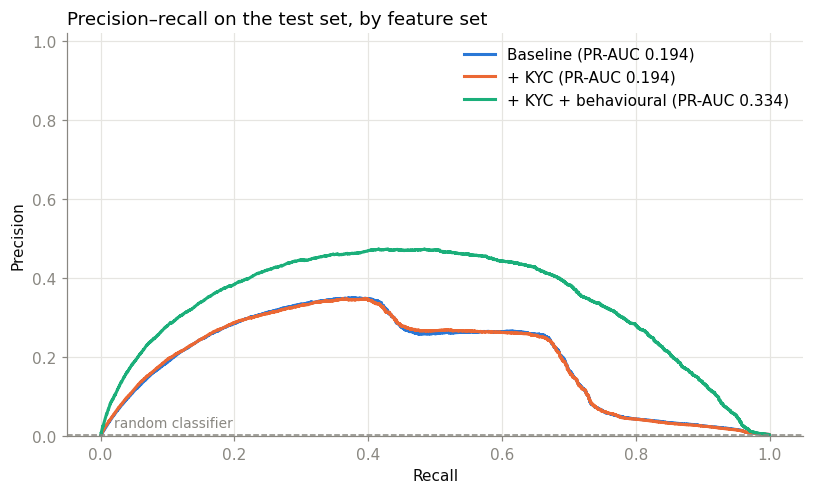

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for name in feature_sets:
    p, r, _ = precision_recall_curve(y_test, test_probas[name])
    ax.plot(r[:-1], p[:-1], color=SET_COLOURS[name],  # drop sklearn's artificial (recall=0, precision=1) end point
            label=f"{name} (PR-AUC {average_precision_score(y_test, test_probas[name]):.3f})")
ax.axhline(y_test.mean(), color=MUTED, linestyle="--", linewidth=1)
ax.annotate("random classifier", (0.02, y_test.mean()), xytext=(0, 5),
            textcoords="offset points", color=MUTED, fontsize=9)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_ylim(0, 1.02)
ax.set_title("Precision–recall on the test set, by feature set", loc="left")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

## 6. The full model in detail

The rest of the notebook looks at the **+ KYC + behavioural** model.

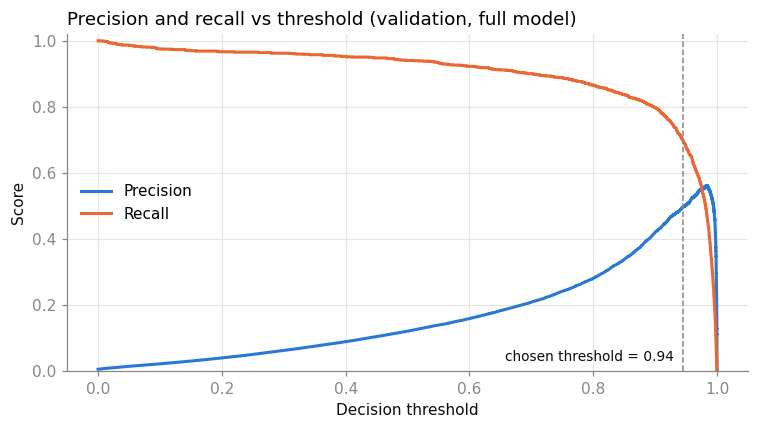

=== Test set, threshold: default 0.5 ===
              precision    recall  f1-score   support

  legitimate      1.000     0.964     0.982    553574
       fraud      0.091     0.925     0.166      2145

    accuracy                          0.964    555719
   macro avg      0.545     0.945     0.574    555719
weighted avg      0.996     0.964     0.978    555719

=== Test set, threshold: tuned 0.94 ===
              precision    recall  f1-score   support

  legitimate      0.999     0.996     0.997    553574
       fraud      0.408     0.676     0.509      2145

    accuracy                          0.995    555719
   macro avg      0.703     0.836     0.753    555719
weighted avg      0.996     0.995     0.996    555719



In [9]:
FULL = "+ KYC + behavioural"
full_cols = feature_sets[FULL]
final_model = final_models[FULL]
test_proba = test_probas[FULL]
val_proba = tuned[FULL]["val_proba"]
threshold = tuned[FULL]["threshold"]

precision, recall, thresholds = precision_recall_curve(y_val, val_proba)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, precision[:-1], color=BLUE, label="Precision")
ax.plot(thresholds, recall[:-1], color=ORANGE, label="Recall")
ax.axvline(threshold, color=MUTED, linestyle="--", linewidth=1)
ax.annotate(f"chosen threshold = {threshold:.2f}", (threshold, 0.03),
            xytext=(-6, 0), textcoords="offset points", ha="right", color=INK, fontsize=9)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.02)
ax.set_title("Precision and recall vs threshold (validation, full model)", loc="left")
ax.legend(frameon=False, loc="center left")
plt.tight_layout()
plt.show()

for name, t in [("default 0.5", 0.5), (f"tuned {threshold:.2f}", threshold)]:
    print(f"=== Test set, threshold: {name} ===")
    print(classification_report(y_test, (test_proba >= t).astype(int),
                                target_names=["legitimate", "fraud"], digits=3))

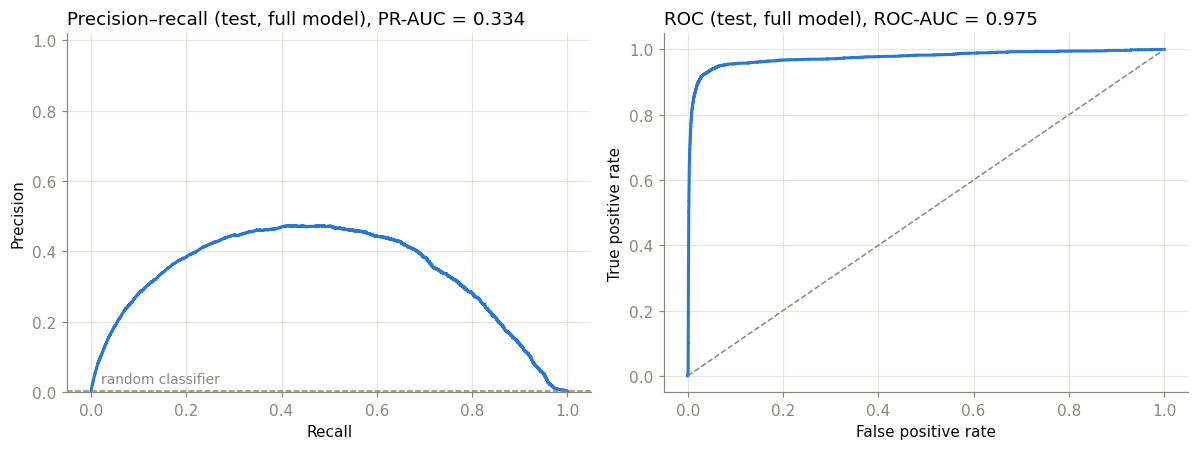

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

p, r, _ = precision_recall_curve(y_test, test_proba)
axes[0].plot(r[:-1], p[:-1], color=BLUE)  # drop sklearn's artificial (recall=0, precision=1) end point
axes[0].axhline(y_test.mean(), color=MUTED, linestyle="--", linewidth=1)
axes[0].annotate("random classifier", (0.02, y_test.mean()), xytext=(0, 5),
                 textcoords="offset points", color=MUTED, fontsize=9)
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_ylim(0, 1.02)
axes[0].set_title(f"Precision–recall (test, full model), PR-AUC = {average_precision_score(y_test, test_proba):.3f}", loc="left")

fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, color=BLUE)
axes[1].plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1)
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title(f"ROC (test, full model), ROC-AUC = {roc_auc_score(y_test, test_proba):.3f}", loc="left")

plt.tight_layout()
plt.show()

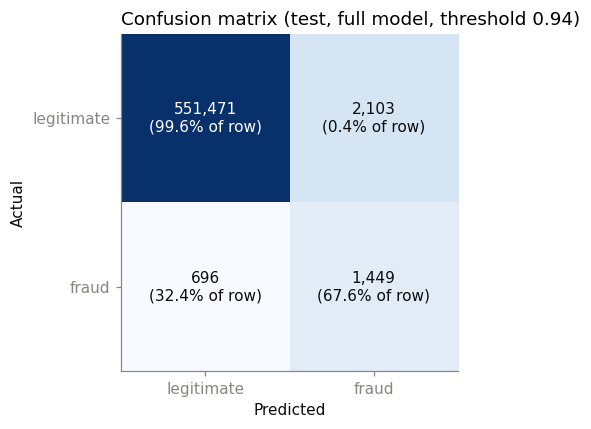

,predicted legitimate,predicted fraud
actual legitimate,551471,2103
actual fraud,696,1449


In [11]:
cm = confusion_matrix(y_test, (test_proba >= threshold).astype(int))
labels = ["legitimate", "fraud"]

fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(np.log10(cm + 1), cmap="Blues")
ax.grid(False)
for i in range(2):
    for j in range(2):
        share = cm[i, j] / cm[i].sum()
        ax.text(j, i, f"{cm[i, j]:,}\n({share:.1%} of row)", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 10 else INK)
ax.set_xticks([0, 1], labels)
ax.set_yticks([0, 1], labels)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion matrix (test, full model, threshold {threshold:.2f})", loc="left")
plt.tight_layout()
plt.show()

pd.DataFrame(cm, index=[f"actual {l}" for l in labels], columns=[f"predicted {l}" for l in labels])

## 7. Coefficients and odds ratios

Because multicollinearity was removed in preprocessing, the coefficients can be read individually:

- **Continuous features:** odds ratio = multiplicative change in the odds of fraud for a **1 standard deviation** increase.
- **Dummies:** odds ratio vs the **baseline category**, which is the most frequent one: `gas_transport` for category, `F` for gender, `TX` for state, `Employed` for employment, `Citizen` for residency, `Document (in person)` for ID verification.

Odds ratio > 1 means higher fraud risk, < 1 lower. These are associations within simulated data, not causal effects, and the KYC fields are synthetic.

In [12]:
feature_names = final_model.named_steps["scale"].get_feature_names_out()
coefs = pd.DataFrame({
    "feature": feature_names,
    "coef": final_model.named_steps["logreg"].coef_[0],
})
coefs["odds_ratio"] = np.exp(coefs["coef"])
coefs["scaled"] = ~coefs["feature"].isin(binary_columns)
coefs = coefs.reindex(coefs["coef"].abs().sort_values(ascending=False).index).reset_index(drop=True)
coefs.head(20).round(3)

,feature,coef,odds_ratio,scaled
0,amt_is_large,2.766,15.900,False
1,category_shopping_pos,-2.095,0.123,False
2,beh_log_amt_sum_24h,2.027,7.592,True
3,category_shopping_net,-1.884,0.152,False
4,category_misc_net,-1.568,0.208,False
5,log_amt,-1.285,0.277,True
6,category_entertainment,-1.220,0.295,False
7,hour_cos,1.054,2.868,True
8,beh_txn_count_24h,-1.048,0.351,True
9,category_travel,-0.933,0.394,False


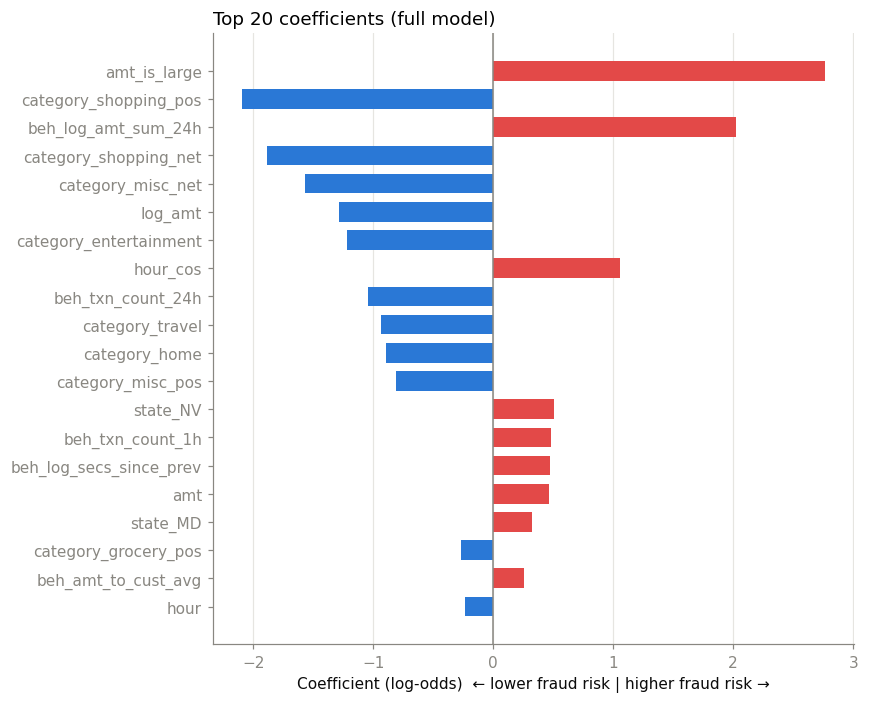

In [13]:
top = coefs.head(20).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top["feature"], top["coef"], color=np.where(top["coef"] > 0, RED, BLUE), height=0.7)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_axisbelow(True)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Coefficient (log-odds)  ← lower fraud risk | higher fraud risk →")
ax.set_title("Top 20 coefficients (full model)", loc="left")
plt.tight_layout()
plt.show()

## 8. Results summary

| Test set (Jun–Dec 2020) | Baseline | + KYC | + KYC + behavioural |
|---|---|---|---|
| PR-AUC (random ≈ 0.004) | 0.194 | 0.194 | **0.334** |
| ROC-AUC | 0.951 | 0.950 | **0.975** |
| Fraud precision @ tuned threshold | 0.264 | 0.262 | **0.408** |
| Fraud recall @ tuned threshold | 0.624 | 0.605 | **0.676** |
| Frauds caught (of 2,145) | 1,339 | 1,298 | **1,449** |
| False alarms | 3,728 | 3,654 | **2,103** |

`C` and the threshold were chosen on validation for each feature set (baseline and + KYC: `C = 0.0001`, threshold ≈ 0.88; full model: `C = 0.001`, threshold 0.94).

**The synthetic KYC adds nothing.** PR-AUC is unchanged (0.194 vs 0.194). This is the expected, honest outcome: the KYC fields were generated without fraud labels, from attributes the model mostly already has (age, city size), and in this dataset fraud is card theft that strikes customers regardless of their profile. The ratios against declared spend and credit limit don't help either, because they are essentially the transaction amount rescaled by a customer-level constant. In real data, KYC tends to matter more for first-party fraud and money laundering (where the customer *is* the bad actor) than for stolen-card fraud like this.

**The behavioural features help a lot.** PR-AUC rises from 0.194 to 0.334 (+72%). The full model catches 110 more frauds *and* raises 1,625 fewer false alarms (2,103 vs 3,728). Roughly **2 in 5 alerts are now real fraud**, up from 1 in 4.

**Reading the behavioural coefficients** (all are conditional on each other):
- `beh_log_amt_sum_24h` (+) with `beh_txn_count_24h` (−): **a lot of money in few transactions** over the past day is the fraud pattern. Many transactions adding up to the same total looks like a normal busy customer.
- `beh_txn_count_1h` (+): several transactions within one hour.
- `beh_log_secs_since_prev` (+): a transaction after an unusually long gap, the typical start of a fraud burst on a quiet card.
- `beh_amt_to_cust_avg` (+): amounts well above the customer's own usual spend.

Amount, time of day and category remain the strongest single signals, and their interpretation from the baseline still holds.

**Limitations / next steps.**
- The KYC result is a property of synthetic data built without labels. It says the *mechanism* (static profile fields) doesn't help against stolen-card fraud here; it can't say how much a real KYC file would help.
- Logistic regression can only add up effects. Tree models (random forest, XGBoost) can learn combinations such as "night + high 24h spend + online category", and are the natural next comparison on the same split and feature sets.